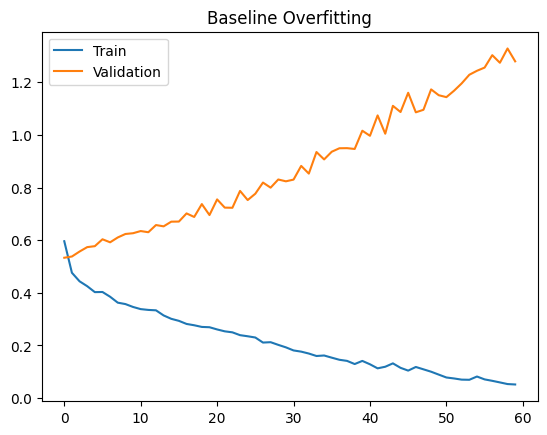

,Model,Train Accuracy,Test Accuracy,Gap
0,Baseline,1.000,0.784,0.216
1,L2 .001,0.973,0.766,0.208
2,L2 .01,0.867,0.775,0.093
3,L2 .1,0.777,0.748,0.029
4,Dropout .2,0.955,0.775,0.180
5,Dropout .3,0.924,0.784,0.140
6,Dropout .5,0.860,0.766,0.094
7,Early Stopping,0.777,0.775,0.002


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import Sequential, layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping

X, y = load_diabetes(return_X_y=True)
y = (y > np.median(y)).astype(int)

Xtr, Xt, ytr, yt = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

Xtr, Xv, ytr, yv = train_test_split(
    Xtr, ytr, test_size=0.2, random_state=42, stratify=ytr)

sc = StandardScaler()
Xtr = sc.fit_transform(Xtr)
Xv = sc.transform(Xv)
Xt = sc.transform(Xt)

def build(lam=0, drop=0):
    m = Sequential([
        layers.Input((Xtr.shape[1],)),
        layers.Dense(256, activation="relu",
                     kernel_regularizer=regularizers.l2(lam)),
        layers.Dropout(drop),
        layers.Dense(128, activation="relu",
                     kernel_regularizer=regularizers.l2(lam)),
        layers.Dropout(drop),
        layers.Dense(1, activation="sigmoid")
    ])
    m.compile("adam", "binary_crossentropy", metrics=["accuracy"])
    return m

results = []
histories = {}

configs = [
    ("Baseline", 0, 0, False),
    ("L2 .001", .001, 0, False),
    ("L2 .01", .01, 0, False),
    ("L2 .1", .1, 0, False),
    ("Dropout .2", 0, .2, False),
    ("Dropout .3", 0, .3, False),
    ("Dropout .5", 0, .5, False),
    ("Early Stopping", 0, 0, True)
]

for name, lam, drop, es in configs:
    model = build(lam, drop)
    cb = [EarlyStopping(patience=6, restore_best_weights=True)] if es else []
    h = model.fit(Xtr, ytr, validation_data=(Xv, yv),
                  epochs=60, batch_size=16, verbose=0,
                  callbacks=cb)
    histories[name] = h
    train_acc = model.evaluate(Xtr, ytr, verbose=0)[1]
    test_acc = model.evaluate(Xt, yt, verbose=0)[1]
    results.append([name, train_acc, test_acc, train_acc-test_acc])

plt.plot(histories["Baseline"].history["loss"], label="Train")
plt.plot(histories["Baseline"].history["val_loss"], label="Validation")
plt.legend()
plt.title("Baseline Overfitting")
plt.show()

display(pd.DataFrame(results, columns=[
    "Model", "Train Accuracy", "Test Accuracy", "Gap"
]).round(3))
